# Deep Learning (Fall 2026) - Homework 4

---



*Developed by Hongtau Wu & Suzanna Sia*

This notebook contains all starter code for Homework 4. Please read the written assignment carefully to ensure you include all necessary outputs in your final report. Your final submission (a single zip file) should include this notebook (.ipynb file) and a PDF of this notebook with all cell outputs.

## Problem 1a)

### Imports

In [2]:
## External Libararies
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

### Data Loading

In [3]:
## Spectify Path to Provided Data Here
DATA_PATH = 'fall26_hw4_prob1_data.npy'

## Load Data and Check Dimensionality
data = np.load(DATA_PATH)
Y = data[:,2]
X = data[:,0:2]
print("Y:", Y.shape)
print("X:", X.shape)

## Polygon Boundaries
p = [[[500, 1000], [300, 800], [400, 600], [600, 600], [700, 800]],
     [[500, 600], [100, 400], [300, 200], [700, 200], [900, 400]]]
p = np.asarray(p)
p0 = p[0]
p1 = p[1]

Y: (60000,)
X: (60000, 2)


### Visualization Code

Do not touch any of the visualization code below.

In [4]:
## Helper code for visualisation (No Need to Touch)
def visualize_polygons(p0, p1):
    fig, ax = plt.subplots()
    patches = []
    polygon1 = Polygon(p0, closed=True)
    polygon2 = Polygon(p1, closed=True)
    patches.append(polygon1)
    patches.append(polygon2)
    p = PatchCollection(patches, cmap=matplotlib.cm.jet, alpha=0.4)
    ax.add_collection(p)
    ax.autoscale_view()
    plt.show()

def visualize_datapoints(X, Y):
    assert(X.shape[0] == Y.shape[0])
    fig, ax = plt.subplots()
    npts = 60000
    col = np.where(Y[:npts]==1,'m','b')
    x1 = X[:npts][:,0]
    x2 = X[:npts][:,1]
    ax.scatter(x1, x2, s=0.5, c=col, zorder=1)
    plt.show()

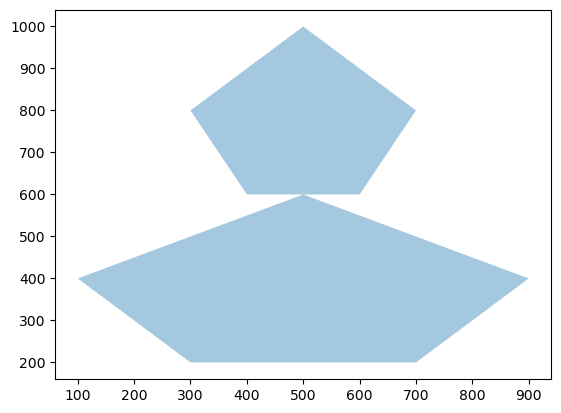

In [5]:
visualize_polygons(p0,p1)

### Problem 1a)

Please fill in all code blocks marked with a #TODO.

In [6]:
def threshold_activation1(x):
    y = np.copy(x)
    y[y <= 0] = 0
    y[y > 0] = 1
    return y


def and_gate(x):
    """
    Implement an "and" gate
    """
    for item in x:
        if (item != 1):
            return 0
    return 1


def or_gate(x):
    """
    #TODO: Implement an "or" gate
    """
    # TODO:
    for item in x:
        if (item != 0):
            return 1
    return 0

def analytical_parameters(p0, p1):
    """

    """
    ## Dimensionality
    x_dim = 2
    class_num = 2
    hidden_unit_num = 10
    # First Layer Parameter
    W = np.zeros((hidden_unit_num, x_dim))
    b = np.zeros((hidden_unit_num, 1))
    for i in range(5):
        # First polygon
        x1 = p0[i, 0]
        y1 = p0[i, 1]
        x2 = p0[(i+1)%5, 0]
        y2 = p0[(i+1)%5, 1]
        W[i, :] = [y1 - y2, x2 - x1]
        b[i, :] = x1 * y2 - x2 * y1
        # Second polygon
        x1 = p1[i, 0]
        y1 = p1[i, 1]
        x2 = p1[(i+1)%5, 0]
        y2 = p1[(i+1)%5, 1]
        W[i + 5, :] = [y1 - y2, x2 - x1]
        b[i + 5, :] = x1 * y2 - x2 * y1
    return W,b

def predict_output_v1(X, W, b):
    """

    """
    predictions = []
    for idx in range(data.shape[0]):
        x = np.reshape(X[idx, :], (2, 1))
        # First layer
        first_layer_output = np.matmul(W, x) + b
        first_layer_output = threshold_activation1(first_layer_output)
        # Second layer
        first_polygon = first_layer_output[0:5, :]
        second_polygon = first_layer_output[5:10, :]
        first_gate_output = and_gate(first_polygon)
        second_gate_output = and_gate(second_polygon)
        # Output layer
        input_to_final_gate = [first_gate_output, second_gate_output]
        prediction = or_gate(input_to_final_gate)
        predictions.append(prediction)
    return predictions

def predict_output_v2(X, W, b):
    """
    #TODO: Update usage of the gates in this function
    """
    ## Cache of Predictions
    predictions = []
    ## Cycle Through Data Points
    for idx in range(data.shape[0]):
        x = np.reshape(X[idx, :], (2, 1))
        # First layer
        first_layer_output = np.matmul(W, x) + b
        first_layer_output = threshold_activation1(first_layer_output)
        # Second layer
        first_polygon = first_layer_output[0:5, :]
        second_polygon = first_layer_output[5:10, :]
        first_gate_output = and_gate(first_polygon)
        second_gate_output = and_gate(second_polygon)
        # Output layer
        input_to_final_gate = [first_gate_output]
        prediction = or_gate(input_to_final_gate)
        predictions.append(prediction)
    return predictions

def calc_accuracy(true_y, pred_y):
    """

    """
    true_prediction_num = 0
    for i, py in enumerate(pred_y):
        if py == true_y[i]:
            true_prediction_num += 1
    accuracy = true_prediction_num / len(pred_y)
    print("Accuracy: ", accuracy)
    return accuracy

*Sanity check:* If you correctly implemented the 'and gate' and 'or gate', all points should be classified correctly when you make predictions using `predict_output_v1()`

Accuracy:  1.0


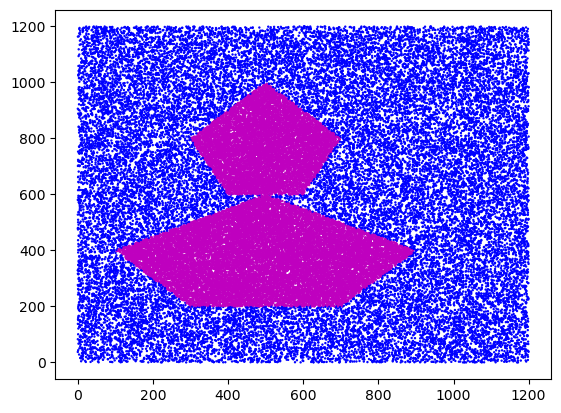

In [7]:
## Load Our Parameters
W, b = analytical_parameters(p0, p1)

## Make Predictions
pred_Y = predict_output_v1(X, W, b)

## Compute Accuracy
acc = calc_accuracy(Y, pred_Y)
assert (acc == 1)

## Visualize Predictions
visualize_datapoints(X, np.array(pred_Y))

In the code above, change the gates in `predict_output_v2()` such that only the points in the top polygon are classified correctly. Visualize your result, report the accuracy of this model, and attach it to the submission.

To further clarify, you should **only** change the usage of the gating functions, not the code inside the gating function itself.

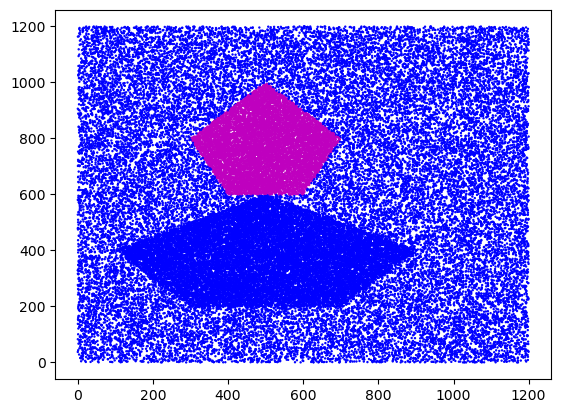

In [8]:
## Load Our Parameters
W, b = analytical_parameters(p0, p1)

## Make Predictions
pred_Y = predict_output_v2(X, W, b)

## Visualize Predictions
visualize_datapoints(X, np.array(pred_Y))

## Problem 1b-d)

Complete problems 1b through 1d in the space below. Please use markdown to clearly distinguish your answers for each part. Include appropriate visualizations generated here in your final report.

## Problem 1b

Splitting our data: "Use gradient descent to optimize the parameters. You should expect an average accuracy greater than 90%. Please use the first 50000 points as your training set and
the remaining 10000 as your test set. You may also want to normalize (i.e. center and scale) the data before training."

In [9]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Convert the two-pentagons data to PyTorch tensors
xTensor = torch.tensor(X, dtype=torch.float32)
yTensor = torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

#Splinting my testing and training data
X_train_raw = xTensor[:50000]
Y_train = yTensor[:50000]
X_test_raw = xTensor[50000:]
Y_test = yTensor[50000:]

#Normalize the mean
train_mean = X_train_raw.mean(dim=0, keepdim=True)
train_std = X_train_raw.std(dim=0, keepdim=True)

X_train = (X_train_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

print("Training X/Y:", X_train.shape, Y_train.shape)
print("Testing X/Y:", X_test.shape, Y_test.shape)

Training X/Y: torch.Size([50000, 2]) torch.Size([50000, 1])
Testing X/Y: torch.Size([10000, 2]) torch.Size([10000, 1])


Does i-iii of b

“Use 2 hidden layers, and 1 output layer with binary-cross-entropy loss.”
“Use 10 nodes in the first hidden layer, 2 nodes in the second hidden layer, and 1 output node.”
“Initialize the weights using Xavier Initialization.”

In [10]:
class PentagonsMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(2, 10)
        self.layer2 = nn.Linear(10, 2)
        self.output_layer = nn.Linear(2, 1)

        self.sigmoid = nn.Sigmoid()

        #Xavier initialization for every linear layer
        for layer in [self.layer1, self.layer2, self.output_layer]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        x = self.sigmoid(self.layer1(x))
        x = self.sigmoid(self.layer2(x))
        x = self.sigmoid(self.output_layer(x))
        return x

1b - IV - You may use any combination of batch size, training epochs, and learning rate.

In [11]:
#Hyperparameters for short test
batchSize = 1000
learningRate = 0.1
shortEpoch = 10

#Package the training tensors into shuffled mini-batches
train_dataset = TensorDataset(X_train, Y_train)
train_loader = DataLoader(
    train_dataset,
    batch_size=batchSize,
    shuffle=True
)

print("Number of training batches:", len(train_loader))

Number of training batches: 50


In [12]:
def train_one_run(seed, epochs, model_class=PentagonsMLP, lr=learningRate, shouldPrint=False):
    # Make each trial reproducible
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = model_class()
    loss_function = nn.BCELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    train_losses = []
    train_accuracies = []
    test_accuracies = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for X_batch, Y_batch in train_loader:
            optimizer.zero_grad()

            predictions = model(X_batch)
            loss = loss_function(predictions, Y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * X_batch.shape[0]

        #Record average training loss for this epoch
        train_losses.append(total_loss / len(train_dataset))

        #Evaluate train and test accuracy after this epoch
        model.eval()
        with torch.no_grad():
            train_pred_labels = (model(X_train) >= 0.5).float()
            test_pred_labels = (model(X_test) >= 0.5).float()

            train_accuracy = (train_pred_labels == Y_train).float().mean().item()
            test_accuracy = (test_pred_labels == Y_test).float().mean().item()

        train_accuracies.append(train_accuracy)
        test_accuracies.append(test_accuracy)
        
        if shouldPrint:
            print(
                f"Epoch {epoch + 1:3d}/{epochs} | "
                f"Loss: {train_losses[-1]:.4f} | "
                f"Train acc: {train_accuracy:.4f} | "
                f"Test acc: {test_accuracy:.4f}"
            )

    history = {
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "test_accuracies": test_accuracies
    }

    return model, history

Test to make sure that it's works for just 10 epochs. "We recommend you design and test your model at a small scale (e.g. 5-10 epochs) before scaling up for the final run."

In [13]:
model, history = train_one_run(seed=0, epochs=shortEpoch, shouldPrint=True)

print("Final training accuracy:", history["train_accuracies"][-1])
print("Final test accuracy:", history["test_accuracies"][-1])

Epoch   1/10 | Loss: 0.6893 | Train acc: 0.5679 | Test acc: 0.5624
Epoch   2/10 | Loss: 0.6875 | Train acc: 0.6318 | Test acc: 0.6308
Epoch   3/10 | Loss: 0.6859 | Train acc: 0.6299 | Test acc: 0.6272
Epoch   4/10 | Loss: 0.6841 | Train acc: 0.6112 | Test acc: 0.6049
Epoch   5/10 | Loss: 0.6822 | Train acc: 0.6270 | Test acc: 0.6252
Epoch   6/10 | Loss: 0.6801 | Train acc: 0.6085 | Test acc: 0.6032
Epoch   7/10 | Loss: 0.6778 | Train acc: 0.6211 | Test acc: 0.6194
Epoch   8/10 | Loss: 0.6754 | Train acc: 0.6358 | Test acc: 0.6327
Epoch   9/10 | Loss: 0.6727 | Train acc: 0.6334 | Test acc: 0.6313
Epoch  10/10 | Loss: 0.6699 | Train acc: 0.6288 | Test acc: 0.6278
Final training accuracy: 0.6287599802017212
Final test accuracy: 0.6277999877929688


Now let's do it for the 500 epochs

In [14]:
model_0, history_0 = train_one_run(
    seed=0,
    epochs=500,
    shouldPrint=True
)

print("Final training accuracy:", history_0["train_accuracies"][-1])
print("Final test accuracy:", history_0["test_accuracies"][-1])

Epoch   1/500 | Loss: 0.6893 | Train acc: 0.5679 | Test acc: 0.5624
Epoch   2/500 | Loss: 0.6875 | Train acc: 0.6318 | Test acc: 0.6308
Epoch   3/500 | Loss: 0.6859 | Train acc: 0.6299 | Test acc: 0.6272
Epoch   4/500 | Loss: 0.6841 | Train acc: 0.6112 | Test acc: 0.6049
Epoch   5/500 | Loss: 0.6822 | Train acc: 0.6270 | Test acc: 0.6252
Epoch   6/500 | Loss: 0.6801 | Train acc: 0.6085 | Test acc: 0.6032
Epoch   7/500 | Loss: 0.6778 | Train acc: 0.6211 | Test acc: 0.6194
Epoch   8/500 | Loss: 0.6754 | Train acc: 0.6358 | Test acc: 0.6327
Epoch   9/500 | Loss: 0.6727 | Train acc: 0.6334 | Test acc: 0.6313
Epoch  10/500 | Loss: 0.6699 | Train acc: 0.6288 | Test acc: 0.6278
Epoch  11/500 | Loss: 0.6667 | Train acc: 0.6446 | Test acc: 0.6425
Epoch  12/500 | Loss: 0.6635 | Train acc: 0.6353 | Test acc: 0.6333
Epoch  13/500 | Loss: 0.6600 | Train acc: 0.6359 | Test acc: 0.6340
Epoch  14/500 | Loss: 0.6563 | Train acc: 0.6422 | Test acc: 0.6393
Epoch  15/500 | Loss: 0.6525 | Train acc: 0.6433

"Train your model using 5 random seeds and report the mean and standard deviation of the train and test accuracy at the end of 500 epochs." 

In [15]:
seeds = [0, 1, 2, 3, 4]

models = {}
histories = {}

for seed in seeds:
    print(f"Running seed {seed}...")
    model, history = train_one_run(
        seed=seed,
        epochs=500,
        shouldPrint=False
    )
    models[seed] = model
    histories[seed] = history

final_train_accuracies = np.array([histories[seed]["train_accuracies"][-1] for seed in seeds])

final_test_accuracies = np.array([histories[seed]["test_accuracies"][-1] for seed in seeds])

print(
    f"Train accuracy: {final_train_accuracies.mean():.4f} "
    f"± {final_train_accuracies.std(ddof=1):.4f}"
)
print(
    f"Test accuracy:  {final_test_accuracies.mean():.4f} "
    f"± {final_test_accuracies.std(ddof=1):.4f}"
)

Running seed 0...
Running seed 1...
Running seed 2...
Running seed 3...
Running seed 4...
Train accuracy: 0.9308 ± 0.0389
Test accuracy:  0.9388 ± 0.0369


"Attach the plots of training loss and testing accuracy change over epochs."

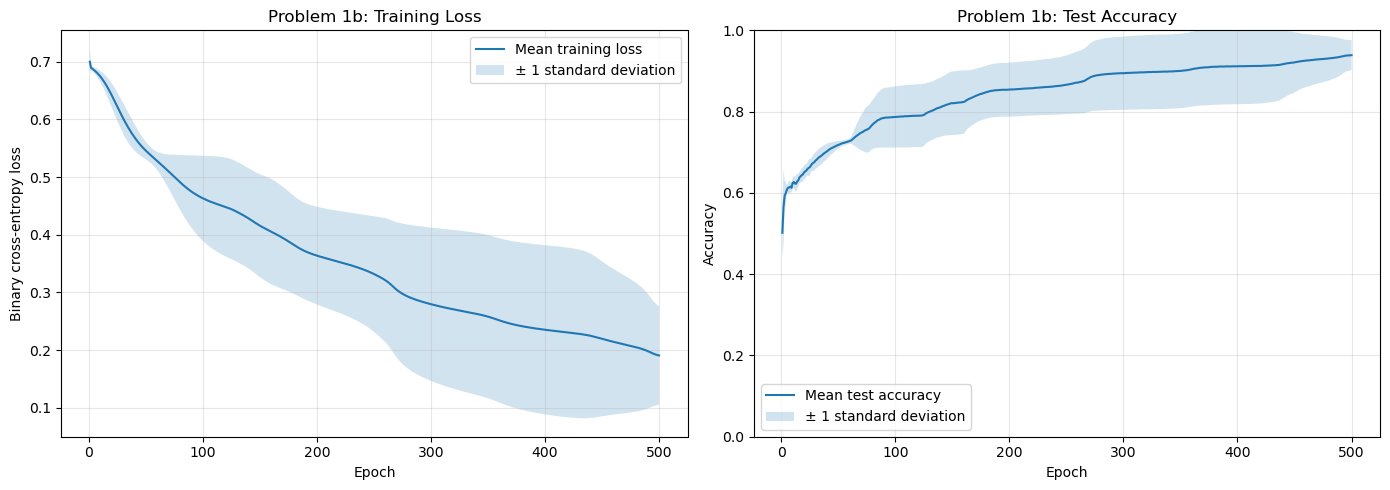

In [16]:
epochs = np.arange(1, 501)

all_train_losses = np.array([histories[seed]["train_losses"] for seed in seeds])

all_test_accuracies = np.array([histories[seed]["test_accuracies"] for seed in seeds])
#Find the averages of all means and std of all the seeds
mean_loss = all_train_losses.mean(axis=0)
std_loss = all_train_losses.std(axis=0, ddof=1)

mean_test_acc = all_test_accuracies.mean(axis=0)
std_test_acc = all_test_accuracies.std(axis=0, ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Training loss
axes[0].plot(epochs, mean_loss, label="Mean training loss")
axes[0].fill_between(
    epochs,
    mean_loss - std_loss,
    mean_loss + std_loss,
    alpha=0.2,
    label="± 1 standard deviation"
)
#Label da axises
axes[0].set_title("Problem 1b: Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Test accuracy
axes[1].plot(epochs, mean_test_acc, label="Mean test accuracy")
axes[1].fill_between(
    epochs,
    mean_test_acc - std_test_acc,
    mean_test_acc + std_test_acc,
    alpha=0.2,
    label="± 1 standard deviation"
)
#Label da axises
axes[1].set_title("Problem 1b: Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

"In your report, attach the visualization of the test set prediction"

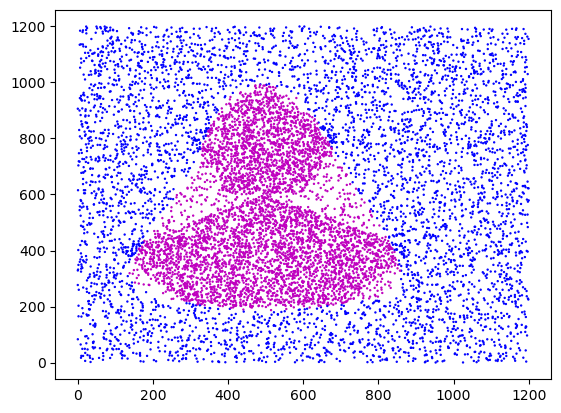

In [17]:
#Seed 0 for visualization
model_for_plot = models[0]
model_for_plot.eval()

with torch.no_grad():
    test_probabilities = model_for_plot(X_test)
    test_predictions = (test_probabilities >= 0.5).int().numpy().flatten()

#Plot it
visualize_datapoints(X[50000:], test_predictions)

## Problem 1c

 "Build an MLP with a larger capacity (increase the depth and width). What do you expect to happen to your model’s ability to learn the appropriate decision boundaries when you increase the depth? Increase the width?"

In [18]:
class LargerPentagonsMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(2, 32)
        self.layer2 = nn.Linear(32, 16)
        self.layer3 = nn.Linear(16, 4)
        self.output_layer = nn.Linear(4, 1)

        self.sigmoid = nn.Sigmoid()

        for layer in [
            self.layer1,
            self.layer2,
            self.layer3,
            self.output_layer
        ]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        x = self.sigmoid(self.layer1(x))
        x = self.sigmoid(self.layer2(x))
        x = self.sigmoid(self.layer3(x))
        x = self.sigmoid(self.output_layer(x))
        return x

"We recommend you design and test your model at a small scale (e.g. 5-10 epochs) before scaling up for the final run."

In [19]:
larger_model, larger_history = train_one_run(
    seed=0,
    epochs=10,
    model_class=LargerPentagonsMLP,
    shouldPrint=True
)

Epoch   1/10 | Loss: 0.6946 | Train acc: 0.4243 | Test acc: 0.4286
Epoch   2/10 | Loss: 0.6939 | Train acc: 0.4829 | Test acc: 0.4832
Epoch   3/10 | Loss: 0.6939 | Train acc: 0.3364 | Test acc: 0.3360
Epoch   4/10 | Loss: 0.6938 | Train acc: 0.4150 | Test acc: 0.4195
Epoch   5/10 | Loss: 0.6937 | Train acc: 0.5234 | Test acc: 0.5247
Epoch   6/10 | Loss: 0.6937 | Train acc: 0.4229 | Test acc: 0.4265
Epoch   7/10 | Loss: 0.6936 | Train acc: 0.5005 | Test acc: 0.4977
Epoch   8/10 | Loss: 0.6936 | Train acc: 0.4823 | Test acc: 0.4828
Epoch   9/10 | Loss: 0.6935 | Train acc: 0.5005 | Test acc: 0.4977
Epoch  10/10 | Loss: 0.6934 | Train acc: 0.4878 | Test acc: 0.4859


Now for the 500

In [20]:
larger_seeds = [0, 1, 2, 3, 4]

larger_models = {}
larger_histories = {}

for seed in larger_seeds:
    print(f"Running seed {seed}...")
    model, history = train_one_run(
        seed=seed,
        epochs=500,
        model_class=LargerPentagonsMLP,
        lr=0.1,
        shouldPrint=False
    )
    larger_models[seed] = model
    larger_histories[seed] = history

larger_final_train = np.array([
    larger_histories[seed]["train_accuracies"][-1]
    for seed in larger_seeds
])

larger_final_test = np.array([
    larger_histories[seed]["test_accuracies"][-1]
    for seed in larger_seeds
])

print(
    f"Train accuracy: {larger_final_train.mean():.4f} "
    f"± {larger_final_train.std(ddof=1):.4f}"
)

print(
    f"Test accuracy:  {larger_final_test.mean():.4f} "
    f"± {larger_final_test.std(ddof=1):.4f}"
)

Running seed 0...
Running seed 1...
Running seed 2...
Running seed 3...
Running seed 4...
Train accuracy: 0.9348 ± 0.0238
Test accuracy:  0.9422 ± 0.0225


iii. Attach the plots of training loss and testing accuracy change over epochs

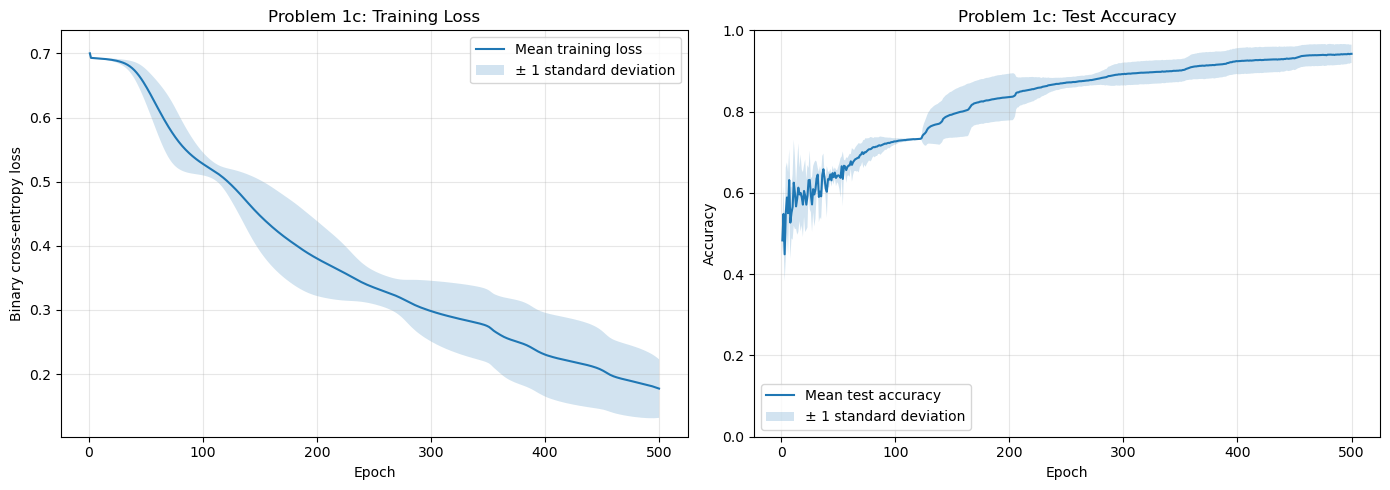

In [21]:
epochs = np.arange(1, 501)

larger_all_train_losses = np.array([
    larger_histories[seed]["train_losses"] for seed in larger_seeds
])

larger_all_test_accuracies = np.array([
    larger_histories[seed]["test_accuracies"] for seed in larger_seeds
])

mean_loss = larger_all_train_losses.mean(axis=0)
std_loss = larger_all_train_losses.std(axis=0, ddof=1)

mean_test_acc = larger_all_test_accuracies.mean(axis=0)
std_test_acc = larger_all_test_accuracies.std(axis=0, ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, mean_loss, label="Mean training loss")
axes[0].fill_between(
    epochs, mean_loss - std_loss, mean_loss + std_loss,
    alpha=0.2, label="± 1 standard deviation"
)
axes[0].set_title("Problem 1c: Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, mean_test_acc, label="Mean test accuracy")
axes[1].fill_between(
    epochs, mean_test_acc - std_test_acc, mean_test_acc + std_test_acc,
    alpha=0.2, label="± 1 standard deviation"
)
axes[1].set_title("Problem 1c: Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

1c) IV Attach the visualization of the prediction for the test set (i.e. polygon figure)

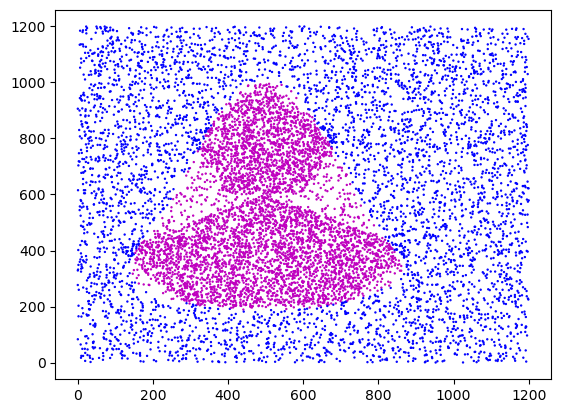

In [22]:
model_for_larger_plot = larger_models[0]
model_for_larger_plot.eval()

with torch.no_grad():
    larger_test_predictions = (
        model_for_larger_plot(X_test) >= 0.5
    ).int().numpy().flatten()

visualize_datapoints(X[50000:], larger_test_predictions)

## Problem 2

All code for Problem 2 should go below. We provide data loaders and relevant imports to get you started. If you are working locally (instead of using Google Colab), we recommend using Conda to install pytorch (https://pytorch.org).

### Imports

In [23]:
## Additional External Libraries (Deep Learning)
import torch
import torch.nn as nn
from torch.autograd import Variable
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as tfs
from PIL import Image
from torchvision.datasets import FashionMNIST
from torch.utils.data import SubsetRandomSampler

### Data Loading

In [24]:
# Hyperparameter (Feel Free to Change These, but Make Sure your Training Loop Still Works as Expected)
TRAIN_BATCH_SIZE = 1000
VAL_BATCH_SIZE = 50
TEST_BATCH_SIZE = 1

# Transform data to PIL images
transforms = tfs.Compose([tfs.ToTensor()])

# Train/Val Subsets
train_mask = range(50000)
val_mask = range(50000, 60000)

FashionMNIST.mirrors = [
    "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
]

# Download/Load Dataset
train_dataset = FashionMNIST('./data', train=True, transform=transforms, download=True)
test_dataset = FashionMNIST('./data', train=False, transform=transforms, download=True)

# Data Loaders
train_dataloader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE, sampler=SubsetRandomSampler(train_mask))
val_dataloader = DataLoader(train_dataset, batch_size=VAL_BATCH_SIZE, sampler=SubsetRandomSampler(val_mask))
test_dataloader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE)

## Problem 2a)

### Design Model

In [25]:
class CNNet(nn.Module):

    """

    """

    def __init__(self):
        """

        """
        ## Inherent Torch Module
        super(CNNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        """

        """
        ##TODO: Setup Forward Pass
        x = self.features(x)
        x = self.classifier(x)
        return x

### Model Training

In [26]:
def train(model,
            optimizer,
            loss,
            lr,
            epochs=50,
            train_dataloader=train_dataloader,
            val_dataloader=val_dataloader,
            test_dataloader=test_dataloader,
            **kwargs):
      """
      #TODO: Implement a training loop
      # Your function can return the model, train loss, and validation accuracy
      """
      if torch.backends.mps.is_available():
            device = torch.device("mps")
      elif torch.cuda.is_available():
            device = torch.device("cuda")
      else:
            device = torch.device("cpu")

      print("Using device:", device)

      model = model.to(device)

      train_losses = []
      train_accuracies = []
      val_accuracies = []

      best_val_accuracy = 0
      best_epoch = 0
      best_state = None

      for epoch in range(epochs):
            model.train()

            total_loss = 0.0
            correct = 0
            total = 0

            for images, labels in train_dataloader:
                  images = images.to(device)
                  labels = labels.to(device)

                  optimizer.zero_grad()

                  outputs = model(images)
                  batch_loss = loss(outputs, labels)

                  batch_loss.backward()
                  optimizer.step()

                  total_loss += batch_loss.item() * images.size(0)
                  predictions = outputs.argmax(dim=1)
                  correct += (predictions == labels).sum().item()
                  total += labels.size(0)

            average_loss = total_loss / total
            train_accuracy = correct / total
            model.eval()
            val_correct = 0
            val_total = 0

            with torch.no_grad():
                  for images, labels in val_dataloader:
                        images = images.to(device)
                        labels = labels.to(device)

                        outputs = model(images)
                        predictions = outputs.argmax(dim=1)

                        val_correct += (predictions == labels).sum().item()
                        val_total += labels.size(0)

            val_accuracy = val_correct / val_total

            train_losses.append(average_loss)
            train_accuracies.append(train_accuracy)
            val_accuracies.append(val_accuracy)

            if val_accuracy > best_val_accuracy:
                  best_val_accuracy = val_accuracy
                  best_epoch = epoch + 1
                  best_state = {
                        name: value.detach().clone()
                        for name, value in model.state_dict().items()
                  }

            print(
            f"Epoch {epoch + 1:2d}/{epochs} | "
            f"Loss: {average_loss:.4f} | "
            f"Train acc: {train_accuracy:.4f} | "
            f"Val acc: {val_accuracy:.4f}"
            )

      #Gets best validation model before the final test evaluation
      model.load_state_dict(best_state)
      model.eval()
      test_correct = 0
      test_total = 0

      with torch.no_grad():
            for images, labels in test_dataloader:
                  images = images.to(device)
                  labels = labels.to(device)

                  outputs = model(images)
                  predictions = outputs.argmax(dim=1)

                  test_correct += (predictions == labels).sum().item()
                  test_total += labels.size(0)

      test_accuracy = test_correct / test_total

      history = {
            "train_losses": train_losses,
            "train_accuracies": train_accuracies,
            "val_accuracies": val_accuracies,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_accuracy,
            "best_test_accuracy": test_accuracy
      }

      return model, history

In [27]:
## Hyperparameters
EPOCH = 5
LR = 0.05

## Setting up the model, optimizer, and loss function
model = CNNet()
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9)
loss_f = nn.CrossEntropyLoss()

In [28]:
## Run Training Loop
out = train(model, optimizer, loss_f, LR)

Using device: mps
Epoch  1/50 | Loss: 1.7644 | Train acc: 0.4301 | Val acc: 0.7107
Epoch  2/50 | Loss: 0.5514 | Train acc: 0.7912 | Val acc: 0.8347
Epoch  3/50 | Loss: 0.4173 | Train acc: 0.8505 | Val acc: 0.8515
Epoch  4/50 | Loss: 0.3631 | Train acc: 0.8710 | Val acc: 0.8716
Epoch  5/50 | Loss: 0.3464 | Train acc: 0.8758 | Val acc: 0.8773
Epoch  6/50 | Loss: 0.3295 | Train acc: 0.8824 | Val acc: 0.8685
Epoch  7/50 | Loss: 0.3069 | Train acc: 0.8896 | Val acc: 0.8903
Epoch  8/50 | Loss: 0.2931 | Train acc: 0.8940 | Val acc: 0.8903
Epoch  9/50 | Loss: 0.2819 | Train acc: 0.8987 | Val acc: 0.8945
Epoch 10/50 | Loss: 0.2755 | Train acc: 0.8999 | Val acc: 0.8941
Epoch 11/50 | Loss: 0.2641 | Train acc: 0.9041 | Val acc: 0.8998
Epoch 12/50 | Loss: 0.2518 | Train acc: 0.9082 | Val acc: 0.8960
Epoch 13/50 | Loss: 0.2500 | Train acc: 0.9079 | Val acc: 0.9016
Epoch 14/50 | Loss: 0.2447 | Train acc: 0.9108 | Val acc: 0.9028
Epoch 15/50 | Loss: 0.2315 | Train acc: 0.9159 | Val acc: 0.9085
Epoch 1

In [29]:
model_2a, history_2a = out

print("Best epoch:", history_2a["best_epoch"])
print("Best validation accuracy:", history_2a["best_val_accuracy"])
print("Test accuracy:", history_2a["best_test_accuracy"])

Best epoch: 39
Best validation accuracy: 0.9206
Test accuracy: 0.9114


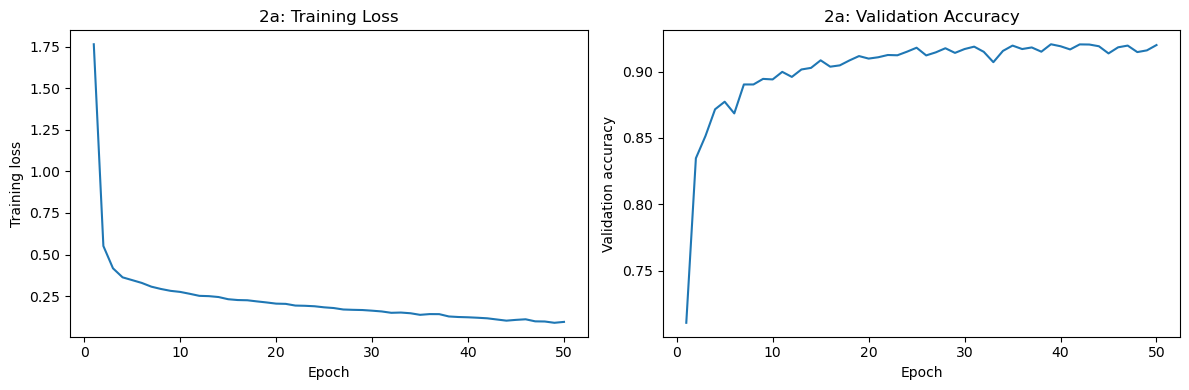

In [30]:
epochs = range(1, len(history_2a["train_losses"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_2a["train_losses"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("2a: Training Loss")

plt.subplot(1, 2, 2)
plt.plot(epochs, history_2a["val_accuracies"])
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("2a: Validation Accuracy")

plt.tight_layout()
plt.show()

## Problem 2b)

Now try to improve your model using additional techniques learned during class. You should be able to use the same training function as above, but will need to create a new model architecture.

### Data Loading

You should maintain the splits from above, but feel free to alter the dataloaders (i.e. transforms) as you wish.

In [31]:
# Hyperparameter (Feel Free to Change These, but Make Sure your Training Loop Still Works as Expected)
TRAIN_BATCH_SIZE = 50
VAL_BATCH_SIZE = 50
TEST_BATCH_SIZE = 1

# Transform data to PIL images
transforms =  tfs.Compose([
    tfs.ToTensor()
])

# Train/Val Subsets
train_mask = range(50000)
val_mask = range(50000, 60000)

# Download/Load Dataset
train_dataset = FashionMNIST('./data', train=True, transform=transforms, download=True)
test_dataset = FashionMNIST('./data', train=False, transform=transforms, download=True)

# Data Loaders
train_dataloader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE, sampler=SubsetRandomSampler(train_mask))
val_dataloader = DataLoader(train_dataset, batch_size=VAL_BATCH_SIZE, sampler=SubsetRandomSampler(val_mask))
test_dataloader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE)

### Model Design

In [32]:
class CNNetImproved(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

### Model Training

In [33]:
EPOCH = 50
LR_2B = 0.001

model_2b = CNNetImproved()
optimizer_2b = torch.optim.Adam(model_2b.parameters(), lr=LR_2B)
loss_f_2b = nn.CrossEntropyLoss()

model_2b, history_2b = train(
    model_2b, optimizer_2b, loss_f_2b, LR_2B, epochs=EPOCH
)

Using device: mps
Epoch  1/50 | Loss: 0.6434 | Train acc: 0.7726 | Val acc: 0.8597
Epoch  2/50 | Loss: 0.3613 | Train acc: 0.8715 | Val acc: 0.8874
Epoch  3/50 | Loss: 0.3020 | Train acc: 0.8925 | Val acc: 0.8984
Epoch  4/50 | Loss: 0.2749 | Train acc: 0.9020 | Val acc: 0.8976
Epoch  5/50 | Loss: 0.2517 | Train acc: 0.9088 | Val acc: 0.9097
Epoch  6/50 | Loss: 0.2292 | Train acc: 0.9193 | Val acc: 0.9092
Epoch  7/50 | Loss: 0.2156 | Train acc: 0.9224 | Val acc: 0.9108
Epoch  8/50 | Loss: 0.2018 | Train acc: 0.9275 | Val acc: 0.9175
Epoch  9/50 | Loss: 0.1940 | Train acc: 0.9288 | Val acc: 0.9178
Epoch 10/50 | Loss: 0.1799 | Train acc: 0.9355 | Val acc: 0.9187
Epoch 11/50 | Loss: 0.1724 | Train acc: 0.9377 | Val acc: 0.9218
Epoch 12/50 | Loss: 0.1608 | Train acc: 0.9422 | Val acc: 0.9191
Epoch 13/50 | Loss: 0.1506 | Train acc: 0.9451 | Val acc: 0.9244
Epoch 14/50 | Loss: 0.1426 | Train acc: 0.9480 | Val acc: 0.9252
Epoch 15/50 | Loss: 0.1345 | Train acc: 0.9519 | Val acc: 0.9210
Epoch 1

In [34]:
print("Best epoch:", history_2b["best_epoch"])
print("Best validation accuracy:", history_2b["best_val_accuracy"])
print("Test accuracy:", history_2b["best_test_accuracy"])

Best epoch: 28
Best validation accuracy: 0.9289
Test accuracy: 0.9209


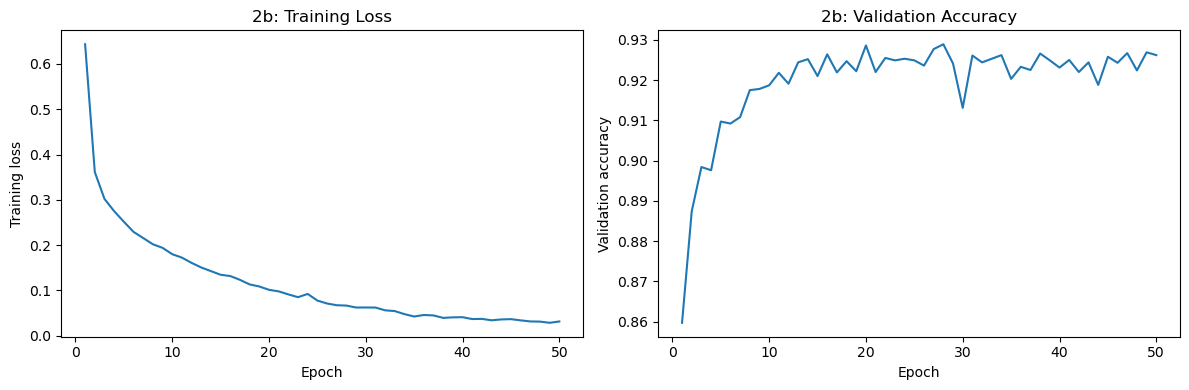

In [35]:
epochs = range(1, len(history_2b["train_losses"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_2b["train_losses"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("2b: Training Loss")

plt.subplot(1, 2, 2)
plt.plot(epochs, history_2b["val_accuracies"])
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("2b: Validation Accuracy")

plt.tight_layout()
plt.show()

## Problem 2c)

Write down your response in the final report.